
# Fase 2 — Análisis inferencial
## Acceso a Internet en los hogares paraguayos — EPHC 2025

**Objetivo:** contrastar las cinco hipótesis derivadas de la Fase 1.

**Decisiones fijadas antes del análisis**
- Nivel de significancia: α = 0,05.
- Corrección por comparaciones múltiples: **Bonferroni**.
- Semilla bootstrap: 42.
- Unidad de análisis: hogar.
- Variable objetivo del proyecto: `TIENE_INTERNET`.

> **Limitación:** la EPHC utiliza un diseño muestral complejo y cada hogar posee `FACTOR`. Las pruebas estándar de `scipy.stats` usadas en esta fase no modelan explícitamente el diseño complejo ni sus varianzas. `FACTOR` se conserva para trazabilidad, pero no se usa como peso en estos contrastes.



## 1. Carga y revisión de datos


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import chi2_contingency, mannwhitneyu, spearmanr, shapiro, levene

df = pd.read_csv("dataset_limpio_internet_hogares.csv")

print("Dimensiones:", df.shape)
display(df.head())

variables = [
    "AREA_DESC", "TIENE_INTERNET", "NIVEL_EDUC_JEFE",
    "IPCM", "ANIOS_ESTUDIO_JEFE", "TOTAL"
]
display(df[variables].isna().sum().to_frame("faltantes"))


Dimensiones: (17092, 21)


,UPM,NVIVI,NHOGA,DPTO,DPTO_NOMBRE,AREA,AREA_DESC,TOTAL,V23A1,TIENE_INTERNET,...,V23C2,EDAD_JEFE,SEXO_JEFE_DESC,ANIOS_ESTUDIO_JEFE,NIVEL_EDUC_JEFE,CAT_OCUP_JEFE_DESC,IPCM,QUINTIL_ING,DECIL_ING,FACTOR
0,14,13,1,0,Asunción,1,Urbana,2,1,1,...,6.0,65,Hombre,15.0,4. Superior (13+ años),Inactivo/No aplica,9.470323e+06,5,10,100
1,14,15,1,0,Asunción,1,Urbana,2,6,0,...,NaN,78,Hombre,6.0,2. Básica completa (6-9 años),Inactivo/No aplica,2.080500e+06,4,7,124
2,14,16,1,0,Asunción,1,Urbana,3,1,1,...,6.0,40,Hombre,17.0,4. Superior (13+ años),Empleado/a privado/a,3.535490e+06,5,9,138
3,14,26,1,0,Asunción,1,Urbana,2,6,1,...,6.0,32,Hombre,12.0,3. Media/Bachillerato (10-12 años),Empleado/a privado/a,3.671471e+06,5,9,183
4,14,35,1,0,Asunción,1,Urbana,2,6,1,...,6.0,24,Hombre,12.0,3. Media/Bachillerato (10-12 años),Empleado/a privado/a,3.457301e+06,5,9,120


,faltantes
AREA_DESC,0
TIENE_INTERNET,0
NIVEL_EDUC_JEFE,2
IPCM,0
ANIOS_ESTUDIO_JEFE,2
TOTAL,0



## 2. Hipótesis estadísticas

### H1 — Área e Internet
- H₀: p_urbana = p_rural.
- H₁: p_urbana ≠ p_rural.
- Natural: la proporción de hogares con Internet es igual en ambas áreas frente a la alternativa de que sea distinta.

### H2 — Educación e Internet
- H₀: acceso a Internet y nivel educativo son independientes.
- H₁: al menos una proporción educativa difiere.
- Natural: el nivel educativo del jefe/a no guarda relación con Internet frente a la alternativa de que sí guarda relación.

### H3 — Ingreso e Internet
- H₀: la distribución de `IPCM` es igual en hogares con y sin Internet.
- H₁: las distribuciones difieren.
- Natural: conectados y no conectados tienen la misma distribución de ingresos frente a la alternativa de que difieren.

### H4 — Años de estudio e ingreso
- H₀: ρ = 0.
- H₁: ρ ≠ 0.
- Natural: años de estudio e ingreso no tienen relación monotónica frente a la alternativa de que sí la tienen.

### H5 — Tamaño del hogar e Internet
- H₀: la distribución de `TOTAL` es igual en hogares con y sin Internet.
- H₁: las distribuciones difieren.
- Natural: el tamaño del hogar no se relaciona con Internet frente a la alternativa de que sí se relaciona.



## 3. Verificación de supuestos

**Independencia:** depende principalmente del diseño de observación. La unidad es el hogar, pero el diseño complejo de la EPHC no se modela explícitamente en estas pruebas; por eso se documenta como limitación.

**Normalidad:** se verifica con Shapiro-Wilk y Q-Q. Para evitar una sensibilidad excesiva por el tamaño muestral, Shapiro se calcula sobre una submuestra de hasta 5.000 casos.

**Homogeneidad de varianzas:** se verifica con Levene como diagnóstico complementario.

Para H3 y H5, si la normalidad no resulta razonable, se utiliza Mann-Whitney en vez de una comparación paramétrica simple de medias. H1 y H2 son categóricas, por lo que Shapiro y Levene no aplican. H4 usa Spearman, que no requiere normalidad bivariada.


IPCM | Shapiro-Wilk W=0.553952, p=1.063e-77


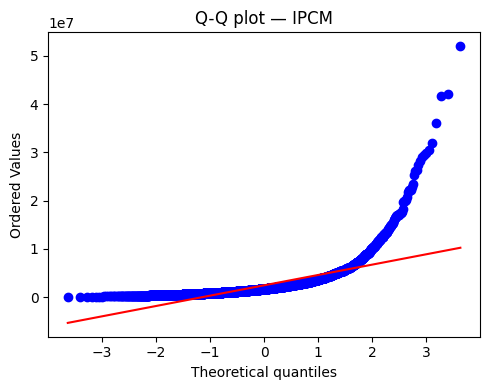

IPCM | Levene=167.175542, p=4.620e-38

TOTAL | Shapiro-Wilk W=0.897993, p=1.518e-49


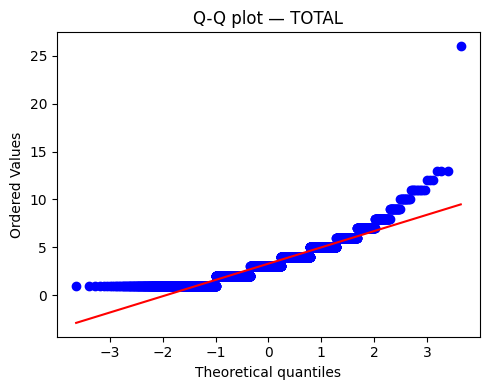

TOTAL | Levene=29.293468, p=6.304e-08



In [2]:

for variable in ["IPCM", "TOTAL"]:
    serie = df[variable].dropna()
    muestra = serie.sample(
        n=min(5000, len(serie)),
        random_state=42
    )

    W, p_shapiro = shapiro(muestra)
    print(f"{variable} | Shapiro-Wilk W={W:.6f}, p={p_shapiro:.3e}")

    plt.figure(figsize=(5,4))
    stats.probplot(muestra, dist="norm", plot=plt)
    plt.title(f"Q-Q plot — {variable}")
    plt.tight_layout()
    plt.show()

    grupo_con = df.loc[df.TIENE_INTERNET == 1, variable].dropna()
    grupo_sin = df.loc[df.TIENE_INTERNET == 0, variable].dropna()
    stat_lev, p_lev = levene(grupo_con, grupo_sin, center="median")
    print(f"{variable} | Levene={stat_lev:.6f}, p={p_lev:.3e}\n")



### Decisión sobre los supuestos

Los diagnósticos muestran fuerte desviación de normalidad en `IPCM` y `TOTAL` y diferencias de varianzas entre los grupos. Esto respalda mantener **Mann-Whitney** para H3 y H5.

La independencia no se prueba con un test estadístico simple y debe interpretarse según el diseño de la encuesta.



## 4. H1 — Área de residencia e Internet

**Prueba:** chi-cuadrado de independencia.  
**Supuestos relevantes:** independencia y frecuencias esperadas adecuadas.  
**Tamaño del efecto:** V de Cramér.  
**IC clásico:** diferencia de proporciones.  
**IC bootstrap:** misma diferencia de proporciones.


In [3]:

tabla_h1 = pd.crosstab(df.AREA_DESC, df.TIENE_INTERNET)
chi_h1, p_h1, gl_h1, exp_h1 = chi2_contingency(tabla_h1, correction=False)
V_h1 = np.sqrt(
    (chi_h1 / tabla_h1.to_numpy().sum())
    / min(tabla_h1.shape[0]-1, tabla_h1.shape[1]-1)
)

u = tabla_h1.loc["Urbana"]
r = tabla_h1.loc["Rural"]
p_u = u[1] / u.sum()
p_r = r[1] / r.sum()
dif_h1 = p_u - p_r

se_h1 = np.sqrt(
    p_u*(1-p_u)/u.sum()
    + p_r*(1-p_r)/r.sum()
)
ic_h1_clasico = (
    dif_h1 - 1.96*se_h1,
    dif_h1 + 1.96*se_h1
)

rng = np.random.default_rng(42)
B = 2000
urb_bin = np.r_[np.ones(int(u[1])), np.zeros(int(u[0]))]
rur_bin = np.r_[np.ones(int(r[1])), np.zeros(int(r[0]))]
boot_h1 = np.empty(B)

for i in range(B):
    boot_h1[i] = (
        rng.choice(urb_bin, len(urb_bin), True).mean()
        - rng.choice(rur_bin, len(rur_bin), True).mean()
    )

ic_h1_boot = np.quantile(boot_h1, [0.025, 0.975])

print(f"chi2={chi_h1:.3f}; gl={gl_h1}; p={p_h1:.3e}")
print(f"V de Cramér={V_h1:.3f}; mínimo esperado={exp_h1.min():.2f}")
print(f"Urbana={p_u:.3%}; rural={p_r:.3%}; diferencia={dif_h1:.3%}")
print(f"IC clásico=[{ic_h1_clasico[0]:.3%}, {ic_h1_clasico[1]:.3%}]")
print(f"IC bootstrap=[{ic_h1_boot[0]:.3%}, {ic_h1_boot[1]:.3%}]")
display(tabla_h1)


chi2=2964.350; gl=1; p=0.000e+00
V de Cramér=0.416; mínimo esperado=2773.38
Urbana=79.611%; rural=38.787%; diferencia=40.824%
IC clásico=[39.451%, 42.196%]
IC bootstrap=[39.441%, 42.179%]


TIENE_INTERNET,0,1
AREA_DESC,,
Rural,4482,2840
Urbana,1992,7778



### Interpretación H1

Se rechaza H₀. La proporción de hogares con Internet es mucho mayor en el área urbana que en el área rural: aproximadamente **79,61% frente a 38,79%**, una diferencia de **40,8 puntos porcentuales**.

V de Cramér ≈ **0,416**, lo que indica una asociación de magnitud importante en esta muestra. La coincidencia entre IC clásico y bootstrap aporta una comprobación adicional de la incertidumbre estimada.

**No es una relación causal.**



## 5. H2 — Nivel educativo e Internet

**Prueba:** chi-cuadrado de independencia en tabla 4×2.  
**Tamaño del efecto:** V de Cramér.  
**Diagnóstico:** residuos estandarizados.


In [4]:

d2 = df.dropna(subset=["NIVEL_EDUC_JEFE", "TIENE_INTERNET"])
tabla_h2 = pd.crosstab(d2.NIVEL_EDUC_JEFE, d2.TIENE_INTERNET)

chi_h2, p_h2, gl_h2, exp_h2 = chi2_contingency(
    tabla_h2,
    correction=False
)

V_h2 = np.sqrt(
    (chi_h2 / tabla_h2.to_numpy().sum())
    / min(tabla_h2.shape[0]-1, tabla_h2.shape[1]-1)
)

res_h2 = (tabla_h2 - exp_h2) / np.sqrt(exp_h2)

# Bootstrap de V de Cramér usando la distribución multinomial
# de las 8 celdas observadas. Es mucho más eficiente que hacer
# miles de tablas con pd.crosstab.
probs_h2 = tabla_h2.to_numpy().ravel()
probs_h2 = probs_h2 / probs_h2.sum()

rng = np.random.default_rng(42)
B = 2000
conteos = rng.multinomial(
    len(d2),
    probs_h2,
    size=B
)

boot_v_h2 = np.empty(B)

for i in range(B):
    tb = conteos[i].reshape(tabla_h2.shape)
    filas = tb.sum(axis=1, keepdims=True)
    columnas = tb.sum(axis=0, keepdims=True)
    esperadas = filas @ columnas / tb.sum()

    chi_boot = ((tb - esperadas)**2 / esperadas).sum()

    boot_v_h2[i] = np.sqrt(
        (chi_boot / tb.sum())
        / min(tb.shape[0]-1, tb.shape[1]-1)
    )

ic_h2 = np.quantile(boot_v_h2, [0.025, 0.975])

print(f"chi2={chi_h2:.3f}; gl={gl_h2}; p={p_h2:.3e}")
print(f"V de Cramér={V_h2:.3f}; mínimo esperado={exp_h2.min():.2f}")
print(f"IC bootstrap de V=[{ic_h2[0]:.3f}, {ic_h2[1]:.3f}]")

print("\nResiduos estandarizados:")
display(
    pd.DataFrame(
        res_h2,
        index=tabla_h2.index,
        columns=tabla_h2.columns
    )
)


chi2=2770.564; gl=3; p=0.000e+00
V de Cramér=0.403; mínimo esperado=1293.26
IC bootstrap de V=[0.390, 0.415]

Residuos estandarizados:


TIENE_INTERNET,0,1
NIVEL_EDUC_JEFE,,
1. Básica incompleta (0-5 años),27.664271,-21.598178
2. Básica completa (6-9 años),7.875888,-6.148900
3. Media/Bachillerato (10-12 años),-12.214675,9.536298
4. Superior (13+ años),-27.291182,21.306899



### Interpretación H2

Se rechaza H₀. Existe una asociación importante entre nivel educativo e Internet.

Los residuos indican el patrón concreto: los niveles educativos bajos presentan más hogares sin Internet de lo esperado bajo independencia, mientras que los niveles altos presentan más hogares con Internet de lo esperado.

V de Cramér ≈ **0,403**.



## 6. H3 — Ingreso per cápita e Internet

**Prueba:** U de Mann-Whitney.

Se utiliza por la fuerte asimetría de `IPCM`. La comparación se centra en las distribuciones y se reportan las medianas, que representan mejor el ingreso típico que la media en una variable tan asimétrica.

**Tamaño del efecto:** r y correlación biserial de rangos.  
**IC:** bootstrap de la diferencia de medianas.


In [5]:

con_h3 = df.loc[df.TIENE_INTERNET == 1, "IPCM"].dropna().to_numpy()
sin_h3 = df.loc[df.TIENE_INTERNET == 0, "IPCM"].dropna().to_numpy()

U_h3, p_h3 = mannwhitneyu(
    con_h3,
    sin_h3,
    alternative="two-sided",
    method="asymptotic"
)

N_h3 = len(con_h3) + len(sin_h3)
media_U = len(con_h3)*len(sin_h3)/2

todos = np.concatenate([con_h3, sin_h3])
_, frec = np.unique(todos, return_counts=True)
tie_term = (frec**3 - frec).sum()

var_U = (
    len(con_h3)*len(sin_h3)/12
) * (
    (N_h3+1) - tie_term/(N_h3*(N_h3-1))
)

Z_h3 = (U_h3-media_U) / np.sqrt(var_U)
r_h3 = abs(Z_h3) / np.sqrt(N_h3)
rb_h3 = 2*U_h3/(len(con_h3)*len(sin_h3))-1

med_con = np.median(con_h3)
med_sin = np.median(sin_h3)
dif_med = med_con-med_sin

rng = np.random.default_rng(42)
B = 3000
boot_h3 = np.empty(B)

for i in range(B):
    boot_h3[i] = (
        np.median(rng.choice(con_h3, len(con_h3), True))
        - np.median(rng.choice(sin_h3, len(sin_h3), True))
    )

ic_h3 = np.quantile(boot_h3, [0.025, 0.975])

print(f"U={U_h3:.0f}; Z={Z_h3:.3f}; p={p_h3:.3e}")
print(f"r={r_h3:.3f}; r_biserial={rb_h3:.3f}")
print(f"Mediana con={med_con:,.0f} Gs.; sin={med_sin:,.0f} Gs.")
print(f"Diferencia de medianas={dif_med:,.0f} Gs.")
print(f"IC bootstrap=[{ic_h3[0]:,.0f}, {ic_h3[1]:,.0f}] Gs.")


U=53178983; Z=60.107; p=0.000e+00
r=0.460; r_biserial=0.547
Mediana con=2,207,393 Gs.; sin=1,100,000 Gs.
Diferencia de medianas=1,107,393 Gs.
IC bootstrap=[1,070,006, 1,146,805] Gs.



### Interpretación H3

Se rechaza H₀. Los hogares con Internet tienen una distribución de ingreso per cápita distinta de los hogares sin Internet.

Mediana conectados ≈ **2.207.393 Gs.**; mediana no conectados ≈ **1.100.000 Gs.**; diferencia ≈ **1.107.393 Gs.**

El efecto r ≈ **0,460** es apreciable. Esto no significa que Internet cause mayores ingresos: educación, área y otros factores podrían participar.



## 7. H4 — Años de estudio e ingreso

**Prueba:** correlación de Spearman.

Spearman es adecuada para asociación monotónica y no exige normalidad bivariada.


In [6]:

d4 = df.dropna(subset=["ANIOS_ESTUDIO_JEFE", "IPCM"])
x4 = d4["ANIOS_ESTUDIO_JEFE"].to_numpy()
y4 = d4["IPCM"].to_numpy()

rho_h4, p_h4 = spearmanr(x4, y4)

rng = np.random.default_rng(42)
B = 1000
boot_h4 = np.empty(B)

for i in range(B):
    indices = rng.integers(
        0,
        len(x4),
        size=len(x4)
    )
    boot_h4[i] = spearmanr(
        x4[indices],
        y4[indices]
    ).statistic

ic_h4 = np.quantile(boot_h4, [0.025, 0.975])

print(f"n={len(d4)}; rho={rho_h4:.3f}; p={p_h4:.3e}")
print(f"IC bootstrap de rho=[{ic_h4[0]:.3f}, {ic_h4[1]:.3f}]")


n=17090; rho=0.451; p=0.000e+00
IC bootstrap de rho=[0.439, 0.463]



### Interpretación H4

Se rechaza H₀. Hay una **asociación monotónica positiva moderada** entre años de estudio e ingreso per cápita (ρ ≈ **0,451**).

Esto es metodológicamente importante porque muestra que educación e ingreso están relacionados entre sí y pueden actuar como explicaciones parcialmente solapadas de las diferencias de conectividad.



## 8. H5 — Tamaño del hogar e Internet

**Prueba:** U de Mann-Whitney.

**Tamaño del efecto:** r.

Como `TOTAL` es discreta, las medianas pueden permanecer iguales aunque exista una diferencia pequeña en la distribución. Por eso se reporta además la diferencia de medias con IC bootstrap como medida descriptiva complementaria.


In [7]:

con_h5 = df.loc[df.TIENE_INTERNET == 1, "TOTAL"].dropna().to_numpy()
sin_h5 = df.loc[df.TIENE_INTERNET == 0, "TOTAL"].dropna().to_numpy()

U_h5, p_h5 = mannwhitneyu(
    con_h5,
    sin_h5,
    alternative="two-sided",
    method="asymptotic"
)

N_h5 = len(con_h5) + len(sin_h5)
media_U5 = len(con_h5)*len(sin_h5)/2

todos5 = np.concatenate([con_h5, sin_h5])
_, frec5 = np.unique(todos5, return_counts=True)
tie_term5 = (frec5**3-frec5).sum()

var_U5 = (
    len(con_h5)*len(sin_h5)/12
) * (
    (N_h5+1)-tie_term5/(N_h5*(N_h5-1))
)

Z_h5 = (U_h5-media_U5)/np.sqrt(var_U5)
r_h5 = abs(Z_h5)/np.sqrt(N_h5)

media_con5 = con_h5.mean()
media_sin5 = sin_h5.mean()
dif_media5 = media_con5-media_sin5

rng = np.random.default_rng(42)
B = 3000
boot_h5 = np.empty(B)

for i in range(B):
    boot_h5[i] = (
        rng.choice(con_h5, len(con_h5), True).mean()
        - rng.choice(sin_h5, len(sin_h5), True).mean()
    )

ic_h5 = np.quantile(boot_h5, [0.025, 0.975])

print(f"U={U_h5:.0f}; Z={Z_h5:.3f}; p={p_h5:.3e}")
print(f"r={r_h5:.3f}")
print(f"Media con={media_con5:.3f}; sin={media_sin5:.3f}")
print(f"Diferencia de medias={dif_media5:.3f}")
print(f"IC bootstrap=[{ic_h5[0]:.3f}, {ic_h5[1]:.3f}]")
print(f"Mediana con={np.median(con_h5):.1f}; mediana sin={np.median(sin_h5):.1f}")


U=35881248; Z=4.912; p=9.004e-07
r=0.038
Media con=3.320; sin=3.194
Diferencia de medias=0.127
IC bootstrap=[0.071, 0.180]
Mediana con=3.0; mediana sin=3.0



### Interpretación H5

Se rechaza H₀ estadísticamente, pero la relevancia práctica es mínima.

r ≈ **0,038**, la diferencia de medias es ≈ **0,13 personas** y ambas medianas son **3**.

Este contraste demuestra por qué un proyecto de Data Science no debe decir simplemente "p < 0,05". El tamaño del efecto y la magnitud real de la diferencia importan.



## 9. Posible variable de confusión

`AREA_DESC` es una posible variable de confusión en la relación entre educación e Internet.

Conceptualmente:

**Educación ← Área de residencia → Internet**

No se demuestra aquí que sea un confusor efectivo; se identifica como una variable que debe controlarse en un análisis posterior. La razón es que el área puede estar relacionada con educación y está claramente relacionada con la conectividad.

Además, H4 demuestra que educación e ingreso están relacionados. Por eso las pruebas bivariadas no deben interpretarse como efectos independientes.



## 10. Comparaciones múltiples — Bonferroni

Se hicieron cinco contrastes principales. Sin corrección, cada prueba añade posibilidades de falsos positivos. Como pertenecen al mismo conjunto de preguntas del estudio, se corrigen conjuntamente.

Se usa **Bonferroni**, admitido explícitamente por la consigna:

p_ajustado = min(5 × p, 1)

Se decidió el método antes de interpretar la conclusión final.


In [8]:

p_values = np.array([
    p_h1,
    p_h2,
    p_h3,
    p_h4,
    p_h5
], dtype=float)

p_bonf = np.minimum(
    p_values * 5,
    1.0
)

resumen = pd.DataFrame({
    "Hipotesis": [
        "H1 Área ↔ Internet",
        "H2 Educación ↔ Internet",
        "H3 Ingreso ↔ Internet",
        "H4 Educación ↔ Ingreso",
        "H5 Tamaño hogar ↔ Internet"
    ],
    "Prueba": [
        "Chi-cuadrado",
        "Chi-cuadrado",
        "Mann-Whitney",
        "Spearman",
        "Mann-Whitney"
    ],
    "p_original": p_values,
    "p_Bonferroni": p_bonf,
    "Decision": np.where(
        p_bonf < 0.05,
        "Rechazar H0",
        "No rechazar H0"
    )
})

display(resumen)


,Hipotesis,Prueba,p_original,p_Bonferroni,Decision
0,H1 Área ↔ Internet,Chi-cuadrado,0.000000e+00,0.000000,Rechazar H0
1,H2 Educación ↔ Internet,Chi-cuadrado,0.000000e+00,0.000000,Rechazar H0
2,H3 Ingreso ↔ Internet,Mann-Whitney,0.000000e+00,0.000000,Rechazar H0
3,H4 Educación ↔ Ingreso,Spearman,0.000000e+00,0.000000,Rechazar H0
4,H5 Tamaño hogar ↔ Internet,Mann-Whitney,9.003669e-07,0.000005,Rechazar H0



## 11. Tabla resumen para el informe

| Hipótesis | Prueba | Supuestos/diagnóstico | Estadístico | IC 95 % | Efecto | Decisión |
|---|---|---|---|---|---|---|
| H1 Área ↔ Internet | Chi-cuadrado | Frecuencias esperadas + independencia | χ²=2964,35; gl=1; p<0,001 | Δ proporciones clásico [39,45%; 42,20%]; bootstrap [39,44%; 42,18%] | V=0,416 | Rechazar H0 |
| H2 Educación ↔ Internet | Chi-cuadrado | Frecuencias esperadas + independencia | χ²=2770,56; gl=3; p<0,001 | V bootstrap [0,390; 0,415] | V=0,403 | Rechazar H0 |
| H3 Ingreso ↔ Internet | Mann-Whitney | No normalidad; Levene no homogéneo | U=53.178.983; p<0,001 | Δ mediana bootstrap [1.070.549; 1.145.873] Gs. | r=0,460 | Rechazar H0 |
| H4 Educación ↔ Ingreso | Spearman | Asociación monotónica; independencia | ρ=0,451; p<0,001 | ρ bootstrap [0,439; 0,464] | ρ=0,451 | Rechazar H0 |
| H5 Tamaño ↔ Internet | Mann-Whitney | No normalidad; Levene no homogéneo | U=35.881.248; p=9,00×10⁻⁷ | Δ media bootstrap [0,074; 0,180] | r=0,038 | Rechazar H0 |

**Nota:** para chi-cuadrado global no existe un único IC "del chi-cuadrado"; se reporta un IC del tamaño del efecto V de Cramér. Para H5 se reporta un IC bootstrap de la diferencia de medias como medida descriptiva complementaria, además del contraste Mann-Whitney.



## 12. Conclusión de la Fase 2

### Hipótesis
Las cinco hipótesis alternativas encuentran evidencia estadística en la muestra y mantienen esa decisión después de la corrección de Bonferroni.

### Implicaciones
- **H1:** existe una brecha territorial de conectividad muy grande.
- **H2:** educación y conectividad están asociadas de manera importante.
- **H3:** los ingresos difieren de forma apreciable entre hogares conectados y no conectados.
- **H4:** educación e ingreso presentan una asociación positiva moderada.
- **H5:** la diferencia estadística en tamaño de hogar es muy pequeña en términos prácticos.

### Limitaciones
- Muestra de 17.092 hogares: el tamaño facilita detectar diferencias pequeñas.
- La EPHC tiene diseño complejo; estas pruebas estándar no incorporan explícitamente estratos, conglomerados ni `FACTOR`.
- La Fase 1 documentó cobertura y precisión desigual por dominios; por ello las cifras no ponderadas no deben presentarse como estimaciones nacionales definitivas.
- Es un corte anual transversal: no hay dependencia temporal que modelar, ni secuencia temporal para hablar de causalidad.
- Los análisis son bivariados y pueden estar afectados por confusión entre área, educación e ingreso.

### Variables candidatas para Fase 3
Para predecir `TIENE_INTERNET`, la evidencia de Fase 2 da prioridad a:
1. `AREA_DESC`
2. `NIVEL_EDUC_JEFE` y/o `ANIOS_ESTUDIO_JEFE`
3. `IPCM`

`TOTAL` queda como candidata secundaria por su efecto pequeño.

La Fase 3 deberá validar estas variables con separación train/test, línea base, varios modelos, validación cruzada, métricas y análisis de errores.



## 13. Correcciones y continuidad respecto de la Fase 1

La consigna pide listar las correcciones recibidas del docente.

**No se recibió en los materiales disponibles una devolución concreta respecto a correcciones de la Fase 1**, por lo que no se inventan correcciones.

Esta Fase 2 sí verifica explícitamente los elementos que exige la rúbrica: hipótesis formales y naturales, supuestos, variedad de pruebas, tamaños de efecto, intervalos, bootstrap frente a clásico, comparación múltiple, confusor, significancia frente a relevancia y cierre hacia Fase 3.
